# AAPL meta-labeling strategy (v7)

**The question:** a simple trend rule decides *when* to be long AAPL. Can machine learning decide *how much* to bet on each signal, and beat both the rule and buy & hold once tested without look-ahead?

This is López de Prado's meta-labeling as intended: the **primary model** picks the side, the **secondary (meta) model** only sizes or filters the bet. It reworks an earlier AAPL notebook of mine (not included in this repo).

| Original notebook | v7 | Why |
|---|---|---|
| Rebased CSV, AAPL 2015–2025 | yfinance OHLCV from 2000 for AAPL + 29 other long-listed large caps, SPY, VIX, FRED | 379 events were far too few to learn from; models train on events pooled across 30 stocks |
| "Dollar bars" from price × volume *ratio*, threshold from the full sample | CUSUM filter on daily returns, threshold = `cusum_k` × volatility known at that close | The old bar size and CUSUM threshold used future data |
| LSTM predicts direction, XGBoost meta-model trained on the LSTM's *in-sample* predictions (100% train accuracy) | Primary = 200-day trend rule (no fitting); meta-models predict whether each trend trade wins | The meta-model now learns from real outcomes, not memorized ones |
| Fixed ±2% barriers, horizon of 10 *events* | Barriers ± `pt_mult`/`sl_mult` × σ × √20, horizon 20 *trading days*, entry at the next open | Barriers scale with volatility; time is measured in days |
| One 70/15/15 split, 47 test bets in 2025 | Purged walk-forward, retrained every year 2008→today, sample weights by label uniqueness | Thousands of out-of-sample bets instead of 47 |
| Price-level ratios, cumulative OBV | Volatility-normalized returns (1–252 d), MACD, vol regime, volume z-score, SPY/VIX context, yield-curve slope and credit spread (lagged) | Stationary inputs from v6 |
| Event-to-event returns, no costs, 1.5× leverage | Daily open-to-open backtest, decide at close, trade at next open, 3 bps costs, max 1× | Realistic |
| One model pair | Logistic regression, XGBoost, the original Attention-LSTM and their average, each as **filter** and **AFML bet sizing** | Compares like with like |
| — | Truncation look-ahead test, shuffled-label check, block bootstrap, cost sensitivity, forward paper-trading log | From v6 |

**Model selection** uses the 30-stock universe in the development period (2008–2022) only. 2023+ is reported separately. AAPL's 2023+ was seen in v3, so the forward log is the only fully clean test.

**Run it:** `Runtime > Run all`, GPU runtime preferred. Estimated 15–30 min (not measured). Results: `results/v7_<timestamp>/`.

In [1]:
import sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'yfinance', 'xgboost'], check=False)

import os
import json
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as TF
import yfinance as yf
import xgboost as xgb
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

TARGET = 'AAPL'
UNIVERSE = ['AAPL', 'MSFT', 'INTC', 'CSCO', 'ORCL', 'IBM', 'QCOM', 'TXN', 'ADBE', 'AMZN',
            'NVDA', 'AMAT', 'MU', 'JPM', 'BAC', 'WFC', 'JNJ', 'PFE', 'MRK', 'PG',
            'KO', 'PEP', 'WMT', 'HD', 'MCD', 'DIS', 'XOM', 'CVX', 'CAT', 'BA']
MARKET, VIX = 'SPY', '^VIX'
FRED_DAILY = {'slope': 'T10Y3M', 'credit': 'BAA10Y'}

CFG = {
    'start': '2000-01-01',
    'end': None,
    'use_drive': False,
    'drive_root': '/content/drive/MyDrive/<your-folder>',
    'local_root': '.',
    'refresh_data': False,
    # features, primary model, events, labels
    'vol_span': 60,
    'trend_window': 200,               # primary model: long when close > 200-day average
    'cusum_k': 2.0,                    # CUSUM threshold in units of daily volatility
    'horizon': 20,                     # vertical barrier, trading days
    'pt_mult': 1.0,                    # profit-take barrier = pt_mult * sigma * sqrt(horizon)
    'sl_mult': 1.0,                    # stop-loss barrier  = sl_mult * sigma * sqrt(horizon)
    'seq_len': 21,                     # Attention-LSTM input window, trading days
    # walk-forward
    'first_test_year': 2008,
    'holdout_start': '2023-01-01',
    'embargo_days': 5,
    # models (fixed in advance)
    'logreg_C': 0.1,
    'xgb': {'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.03, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'min_child_weight': 20, 'tree_method': 'hist', 'n_jobs': -1},
    'hidden': 32,
    'dropout': 0.2,
    'lr': 1e-3,
    'weight_decay': 1e-4,
    'epochs': 15,
    'batch': 256,
    'seeds': [0, 1, 2],
    # backtest
    'cost_bps': 3.0,
    'run_shuffled_check': True,
    'seed': 42,
}
MODELS = ['LogReg', 'XGBoost', 'Attn-LSTM']
ALL_MODELS = MODELS + ['Ensemble']
BASELINES = ['Buy & hold', 'Trend 200d', 'Events: primary only']
META = [f'{m} {k}' for m in ALL_MODELS for k in ('filter', 'sized')]
STRATS = BASELINES + META
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
np.random.seed(CFG['seed'])
torch.manual_seed(CFG['seed'])
print('device:', DEVICE, f'| universe {len(UNIVERSE)} stocks, target {TARGET}')

device: cuda | universe 30 stocks, target AAPL


### Output folders and result logging

In [2]:
def get_root(cfg):
    if IN_COLAB and cfg['use_drive']:
        from google.colab import drive
        drive.mount('/content/drive')
        return cfg['drive_root']
    return cfg['local_root']


ROOT = get_root(CFG)
DATA_DIR = os.path.join(ROOT, 'data')
RUN_ID = pd.Timestamp.now(tz='Europe/London').strftime('v7_%Y%m%d_%H%M%S')
RUN_DIR = os.path.join(ROOT, 'results', RUN_ID)
FORWARD_LOG = os.path.join(ROOT, 'results', 'forward_log_v7.csv')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RUN_DIR, exist_ok=True)
with open(os.path.join(ROOT, 'results', 'LATEST.txt'), 'w') as fh:
    fh.write(RUN_ID + '\n')
SUMMARY = {'run_id': RUN_ID, 'status': 'started'}


def log(*args):
    msg = ' '.join(str(a) for a in args)
    print(msg)
    with open(os.path.join(RUN_DIR, 'log.txt'), 'a', encoding='utf-8') as fh:
        fh.write(msg + '\n')


def save_table(df, name, styler=None):
    df.to_csv(os.path.join(RUN_DIR, f'{name}.csv'))
    with open(os.path.join(RUN_DIR, 'log.txt'), 'a', encoding='utf-8') as fh:
        fh.write(f'\n=== {name} ===\n{df.to_string()}\n\n')
    display(styler if styler is not None else df)


def save_fig(name):
    plt.savefig(os.path.join(RUN_DIR, f'{name}.png'), dpi=110, bbox_inches='tight')
    plt.show()


def save_summary(**kwargs):
    SUMMARY.update(kwargs)
    with open(os.path.join(RUN_DIR, 'summary.json'), 'w') as fh:
        json.dump(SUMMARY, fh, indent=2, default=str)


with open(os.path.join(RUN_DIR, 'config.json'), 'w') as fh:
    json.dump({'cfg': CFG, 'universe': UNIVERSE}, fh, indent=2)
save_summary(versions={'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
                       'torch': torch.__version__, 'yfinance': yf.__version__, 'xgboost': xgb.__version__},
             device=str(DEVICE))
log(f'Results for this run go to: {RUN_DIR}')

Results for this run go to: ./results/v7_20261030_205516


## 1. Data
Daily OHLCV for the 30 stocks, SPY and VIX from yfinance (cached to Drive; set `refresh_data=True` for the latest prices), plus two FRED series: the 10y−3m Treasury slope and the Baa−10y credit spread. The universe is today's long-listed large caps, so it has survivorship bias (see caveats).

In [3]:
def drop_incomplete_session(df):
    """Drop today's bar if the US session may still be open (a partial bar is look-ahead in a backtest)."""
    now = pd.Timestamp.now(tz='America/New_York')
    if len(df) and df.index[-1].date() >= now.date() and now.hour < 17:
        return df.iloc[:-1]
    return df


def download(tk, cfg):
    df = yf.download(tk, start=cfg['start'], end=cfg['end'], auto_adjust=True, progress=False, threads=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    if df.empty:
        return None
    df.index = pd.to_datetime(df.index).tz_localize(None)
    return df[['Open', 'High', 'Low', 'Close', 'Volume']].astype(float)


def download_fred(sid):
    try:
        s = pd.read_csv(f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}',
                        index_col=0, parse_dates=True, na_values='.').iloc[:, 0]
        return s.astype(float).dropna()
    except Exception as e:
        log(f'WARNING: FRED {sid} failed ({e}); that feature will be 0')
        return None


def load_data(cfg):
    path = os.path.join(DATA_DIR, 'stocks_v7.pkl')
    if os.path.exists(path) and not cfg['refresh_data']:
        data = pd.read_pickle(path)
        log(f"Loaded cached data from {path} (downloaded {data['downloaded']:%Y-%m-%d %H:%M})")
        return data
    prices = {}
    for tk in UNIVERSE + [MARKET, VIX]:
        df = download(tk, cfg)
        if df is None:
            log(f'WARNING: no data for {tk}; dropped')
        else:
            prices[tk] = df
    fred = {k: download_fred(sid) for k, sid in FRED_DAILY.items()}
    data = {'prices': prices, 'fred': fred, 'downloaded': pd.Timestamp.now()}
    pd.to_pickle(data, path)
    log(f'Cached {len(prices)} tickers and {sum(v is not None for v in fred.values())} FRED series to {path}')
    return data


data = load_data(CFG)
prices = {tk: drop_incomplete_session(df) for tk, df in data['prices'].items()}
prices = {tk: df[df['Close'] > 0] if tk == VIX else df[(df['Open'] > 0) & (df['Close'] > 0)]
          for tk, df in prices.items()}
assert all(tk in prices for tk in (TARGET, MARKET, VIX)), 'AAPL, SPY and VIX are required'
ASSETS = [tk for tk in UNIVERSE if tk in prices]
dates = prices[MARKET].index


def panel(field):
    df = pd.DataFrame({tk: prices[tk][field] for tk in ASSETS}).reindex(dates).ffill(limit=3)
    for tk in ASSETS:
        df.loc[:prices[tk].index[0] - pd.Timedelta(days=1), tk] = np.nan
    return df


opens, highs, lows, closes, volumes = (panel(f) for f in ['Open', 'High', 'Low', 'Close', 'Volume'])
spy_close = prices[MARKET]['Close'].reindex(dates)
vix_close = prices[VIX]['Close'].reindex(dates).ffill(limit=5)
A, T = len(ASSETS), len(dates)
AI = ASSETS.index(TARGET)
log(f'{A} stocks, {T} sessions, {dates[0]:%Y-%m-%d} to {dates[-1]:%Y-%m-%d}')

Cached 32 tickers and 2 FRED series to ./data/stocks_v7.pkl
30 stocks, 6747 sessions, 2000-01-03 to 2026-10-29


## 2. Features, primary model and events
Every quantity uses data up to the close of day *t* only.
* **Per stock:** volatility-normalized log returns over 1, 5, 21, 63, 126, 252 days; three MACD signals; volatility-regime z-score; distance from the 200-day average; average high–low range ÷ volatility; volume z-score; 63-day return relative to SPY.
* **Market (same for all stocks):** SPY 21- and 63-day returns, VIX z-score and 10-day change, yield-curve slope and credit spread (FRED, lagged one day) and their 3-month changes.
* **Primary model:** long when close > 200-day average.
* **Events:** symmetric CUSUM filter on daily log returns with threshold `cusum_k` × volatility at that close. A **trade signal** is an event on a day the primary model is long.

The truncation test rebuilds everything from data cut at three dates and checks that nothing before the cut changes.

In [5]:
def zscore(s, n):
    return (s - s.rolling(n).mean()) / s.rolling(n).std()


def align(series, index):
    """Align to `index` using only past values (union, forward-fill, reindex)."""
    if series is None or len(series) == 0:
        return pd.Series(np.nan, index=index)
    series = series[~series.index.duplicated(keep='last')].sort_index()
    return series.reindex(series.index.union(index)).ffill().reindex(index)


def fred_frame(fred, index):
    out = {}
    for k in FRED_DAILY:
        s = align(fred.get(k), index).shift(1)                 # published with a one-day lag
        out[k] = s.fillna(0.0) if s.isna().all() else s
    return pd.DataFrame(out, index=index)


def cusum_events(lr, sig, k):
    """Symmetric CUSUM on log returns; event at the close of t when either sum crosses k * sigma_t."""
    ev = np.zeros(len(lr), dtype=bool)
    sp = sn = 0.0
    for t in range(len(lr)):
        r, s = lr[t], sig[t]
        if not (np.isfinite(r) and np.isfinite(s)):
            sp = sn = 0.0
            continue
        sp, sn = max(0.0, sp + r), min(0.0, sn + r)
        if sp > k * s:
            sp, ev[t] = 0.0, True
        elif sn < -k * s:
            sn, ev[t] = 0.0, True
    return ev


def build_all(c, h, l, v, spy, vix, fred, cfg):
    """Features, volatility, primary-model flag and CUSUM events, each using data up to the close of t."""
    lr = np.log(c).diff()
    sig = lr.ewm(span=cfg['vol_span'], min_periods=cfg['vol_span']).std()

    def bcast(s):
        s = s.reindex(c.index)
        return pd.DataFrame(np.repeat(s.values[:, None], c.shape[1], axis=1),
                            index=c.index, columns=c.columns).where(c.notna())

    f = {}
    for k in [1, 5, 21, 63, 126, 252]:
        f[f'ret_{k}'] = np.log(c / c.shift(k)) / (sig * np.sqrt(k))
    for s, L_ in [(8, 24), (16, 48), (32, 96)]:
        m = c.ewm(span=s, adjust=False).mean() - c.ewm(span=L_, adjust=False).mean()
        q = m / c.rolling(63).std()
        f[f'macd_{s}_{L_}'] = q / q.rolling(252).std()
    f['vol_z'] = zscore(np.log(sig), 252)
    sma = c.rolling(cfg['trend_window']).mean()
    f['dist_sma'] = np.log(c / sma) / (sig * np.sqrt(cfg['trend_window']))
    f['range_14'] = np.log(h / l).rolling(14).mean() / sig
    lv = np.log(v.where(v > 0))
    f['volume_z'] = (lv - lv.rolling(63).mean()) / lv.rolling(63).std()
    f['rel_strength_63'] = np.log(c / c.shift(63)).sub(np.log(spy / spy.shift(63)), axis=0) / (sig * np.sqrt(63))

    spy_sig = np.log(spy).diff().ewm(span=cfg['vol_span'], min_periods=cfg['vol_span']).std()
    f['spy_ret_21'] = bcast(np.log(spy / spy.shift(21)) / (spy_sig * np.sqrt(21)))
    f['spy_ret_63'] = bcast(np.log(spy / spy.shift(63)) / (spy_sig * np.sqrt(63)))
    f['vix_z'] = bcast(zscore(np.log(vix), 252))
    f['vix_chg_10'] = bcast(np.log(vix / vix.shift(10)))
    for k in FRED_DAILY:
        f[k] = bcast(fred[k])
        f[f'{k}_chg_63'] = bcast(fred[k] - fred[k].shift(63))
    f = {k: x.replace([np.inf, -np.inf], np.nan) for k, x in f.items()}

    trend = c > sma
    ev = pd.DataFrame(np.column_stack([cusum_events(lr[tk].values, sig[tk].values, cfg['cusum_k'])
                                       for tk in c.columns]), index=c.index, columns=c.columns)
    return f, sig, trend, ev


fred_df = fred_frame(data['fred'], dates)
feats, sigma, trend, cusum = build_all(closes, highs, lows, volumes, spy_close, vix_close, fred_df, CFG)
FEATS = list(feats)
log(f'{len(FEATS)} features: {FEATS}')
log(f"CUSUM events per stock per year: {cusum.sum().mean() / (T / 252):.1f}; "
    f"share of days the primary model is long: {trend.values.mean():.0%}")


def truncation_test(cut_dates):
    failures = {}
    full = {**feats, 'sigma': sigma, 'trend': trend.astype(float), 'events': cusum.astype(float)}
    for cut in cut_dates:
        fred_cut = fred_frame({k: (s.loc[:cut] if s is not None else None) for k, s in data['fred'].items()},
                              dates[dates <= cut])
        f_cut, s_cut, tr_cut, ev_cut = build_all(closes.loc[:cut], highs.loc[:cut], lows.loc[:cut], volumes.loc[:cut],
                                                 spy_close.loc[:cut], vix_close.loc[:cut], fred_cut, CFG)
        part = {**f_cut, 'sigma': s_cut, 'trend': tr_cut.astype(float), 'events': ev_cut.astype(float)}
        bad = [k for k in full if not np.allclose(full[k].loc[:cut].values, part[k].values,
                                                  equal_nan=True, rtol=1e-9, atol=1e-12)]
        if bad:
            failures[str(cut.date())] = bad
            log(f'{cut.date()}: LOOK-AHEAD DETECTED in {bad}')
        else:
            log(f'{cut.date()}: all features, volatility, trend flags and events identical with and without future data')
    save_summary(truncation_test='pass' if not failures else failures)
    assert not failures, f'Look-ahead detected: {failures}'


truncation_test([dates[int(len(dates) * q)] for q in (0.4, 0.7, 0.95)])

22 features: ['ret_1', 'ret_5', 'ret_21', 'ret_63', 'ret_126', 'ret_252', 'macd_8_24', 'macd_16_48', 'macd_32_96', 'vol_z', 'dist_sma', 'range_14', 'volume_z', 'rel_strength_63', 'spy_ret_21', 'spy_ret_63', 'vix_z', 'vix_chg_10', 'slope', 'slope_chg_63', 'credit', 'credit_chg_63']
CUSUM events per stock per year: 44.7; share of days the primary model is long: 63%
2010-09-24: all features, volatility, trend flags and events identical with and without future data
2018-10-09: all features, volatility, trend flags and events identical with and without future data
2025-06-27: all features, volatility, trend flags and events identical with and without future data


## 3. Triple-barrier labels and sample weights
For a trade signal at the close of *t*: enter at the **open of t+1**. Barriers at ± `pt_mult`/`sl_mult` × σₜ × √20 are checked on each close from t+1; the vertical barrier is 20 trading days. If a barrier is touched at the close of day *j*, the trade exits at the **open of j+1**.

**Meta-label** = 1 if the realized open-to-open trade return beats the round-trip cost. **Sample weight** = average uniqueness of the label (AFML ch. 4): overlapping trades share their days, so 30 trades all open in the same week don't count as 30 independent examples.

In [6]:
L, H = CFG['seq_len'], CFG['horizon']
X_all = np.stack([feats[k].values for k in FEATS], axis=-1).transpose(1, 0, 2)       # (asset, day, feature)
SIG = sigma.values.T
feat_ok = np.isfinite(X_all).all(-1) & np.isfinite(SIG) & (SIG > 0)
cs = np.concatenate([np.zeros((A, 1)), np.cumsum(feat_ok, axis=1)], axis=1)
win_ok = np.zeros((A, T), dtype=bool)
win_ok[:, L - 1:] = (cs[:, L:] - cs[:, :T - L + 1]) == L
O, C = opens.values.T, closes.values.T
TREND = trend.values.T
CUSUM = cusum.values.T


def triple_barrier(a, t, cfg):
    """Returns (exit_t, exit_open, trade return, complete). exit_t = T means the trade has not been entered yet."""
    e = t + 1
    if e > T - 2:
        return T, T, np.nan, False
    if not np.isfinite(O[a, e]):
        return None
    width = SIG[a, t] * np.sqrt(cfg['horizon'])
    last = min(t + cfg['horizon'], T - 2)
    path = C[a, e:last + 1] / O[a, e] - 1
    hit = np.nonzero((path >= cfg['pt_mult'] * width) | (path <= -cfg['sl_mult'] * width))[0]
    j = e + hit[0] if len(hit) else last
    complete = bool(len(hit)) or t + cfg['horizon'] <= T - 2
    return j, j + 1, O[a, j + 1] / O[a, e] - 1, complete


ev_a, ev_t = np.nonzero(CUSUM & TREND & win_ok)
rows = [triple_barrier(a, t, CFG) for a, t in zip(ev_a, ev_t)]
keep = np.array([r is not None for r in rows])
EV = pd.DataFrame([r for r in rows if r is not None], columns=['exit_t', 'exit_open', 'ret', 'complete'])
EV.insert(0, 't', ev_t[keep])
EV.insert(0, 'a', ev_a[keep])
EV['date'] = dates[EV['t'].values]
EV['ticker'] = np.array(ASSETS)[EV['a'].values]
EV['y'] = np.where(EV['complete'] & np.isfinite(EV['ret']), (EV['ret'] > 2 * CFG['cost_bps'] / 1e4).astype(float), np.nan)
assert (EV['exit_open'] > EV['t']).all(), 'a trade exits before its signal'

# average uniqueness: a label spans the open-to-open returns of days t+1 .. exit_t
entered = EV['exit_t'].values < T
ea, et, ej = EV['a'].values[entered], EV['t'].values[entered], EV['exit_t'].values[entered]
conc = np.zeros((A, T + 2))
np.add.at(conc, (ea, et + 1), 1)
np.add.at(conc, (ea, ej + 1), -1)
conc = conc.cumsum(1)
U = np.concatenate([np.zeros((A, 1)), np.cumsum(np.where(conc > 0, 1 / np.maximum(conc, 1), 0), axis=1)], axis=1)
w_u = np.ones(len(EV))
w_u[entered] = (U[ea, ej + 1] - U[ea, et + 1]) / (ej - et)
EV['w_unique'] = w_u

hold_days = EV['exit_t'] - EV['t']
label_stats = pd.DataFrame({
    'all stocks': {'trade signals': len(EV), 'labelled': int(EV['y'].notna().sum()), 'win rate': EV['y'].mean(),
                   'avg trade return': EV['ret'].mean(), 'avg holding days': hold_days[entered].mean(),
                   'avg uniqueness': EV['w_unique'].mean()},
    TARGET: {'trade signals': int((EV['a'] == AI).sum()), 'labelled': int(EV.loc[EV['a'] == AI, 'y'].notna().sum()),
             'win rate': EV.loc[EV['a'] == AI, 'y'].mean(), 'avg trade return': EV.loc[EV['a'] == AI, 'ret'].mean(),
             'avg holding days': hold_days[(EV['a'] == AI).values & entered].mean(),
             'avg uniqueness': EV.loc[EV['a'] == AI, 'w_unique'].mean()}}).round(4)
save_table(label_stats, '02_label_stats')

TAB = X_all[EV['a'].values, EV['t'].values]                     # features at the signal close
X_dev = torch.tensor(np.nan_to_num(X_all), dtype=torch.float32, device=DEVICE)
OFFSETS = torch.arange(-L + 1, 1, device=DEVICE)


def get_windows(a, t):
    a = torch.as_tensor(a, device=DEVICE)
    t = torch.as_tensor(t, device=DEVICE)
    return X_dev[a[:, None], t[:, None] + OFFSETS[None, :]]


_w = get_windows(EV['a'].values[[0, -1]], EV['t'].values[[0, -1]]).cpu().numpy()
assert np.allclose(_w[:, -1, :], TAB[[0, -1]], rtol=1e-5, atol=1e-5)
log('Window check passed: every LSTM input window ends at the signal close')

,all stocks,AAPL
trade signals,22018.0000,897.0000
labelled,21958.0000,895.0000
win rate,0.5635,0.6302
avg trade return,0.0083,0.0202
avg holding days,15.8295,15.4303
avg uniqueness,0.3892,0.3676


Window check passed: every LSTM input window ends at the signal close


## 4. Meta-models
All three see the same features and the same uniqueness-weighted labels. Hyperparameters are fixed in `CFG`, not tuned.
* **LogReg:** L2 logistic regression on the features at the signal close (baseline).
* **XGBoost:** shallow boosted trees on the same features, averaged over seeds.
* **Attn-LSTM:** the original notebook's Attention-LSTM, now with one output (probability the trade wins), on the last 21 days of features, averaged over seeds.
* **Ensemble:** average probability of the three.

Features are standardized with the training fold's mean and standard deviation only.

In [7]:
class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attention = nn.Linear(hidden_dim, 1)

    def forward(self, lstm_out):
        attn_weights = torch.softmax(self.attention(lstm_out).squeeze(-1), dim=-1)
        return torch.sum(attn_weights.unsqueeze(-1) * lstm_out, dim=1)


class AttentionLSTM(nn.Module):
    def __init__(self, n_feat, hidden, dropout):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, batch_first=True)
        self.attention = Attention(hidden)
        self.layer_norm = nn.LayerNorm(hidden)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        h = self.layer_norm(self.dropout(self.attention(out)))
        return self.fc(h).squeeze(-1)


def fit_lstm(Xtr, y, w, seed, cfg):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = AttentionLSTM(Xtr.shape[-1], cfg['hidden'], cfg['dropout']).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    yt = torch.tensor(y, dtype=torch.float32, device=DEVICE)
    wt = torch.tensor(w, dtype=torch.float32, device=DEVICE)
    for _ in range(cfg['epochs']):
        model.train()
        perm = torch.as_tensor(rng.permutation(len(y)), device=DEVICE)
        for k in range(0, len(y), cfg['batch']):
            b = perm[k:k + cfg['batch']]
            loss = (TF.binary_cross_entropy_with_logits(model(Xtr[b]), yt[b], reduction='none') * wt[b]).mean()
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
    return model


def predict_lstm(model, X, batch=4096):
    model.eval()
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(model(X[k:k + batch])).cpu().numpy() for k in range(0, len(X), batch)])


def make_windows(idx, mu, sd):
    return ((get_windows(EV['a'].values[idx], EV['t'].values[idx]) - mu) / sd).clamp(-5, 5)


def fit_predict(tr, te, y, w, seeds, cfg):
    """Fit every meta-model on training events `tr`; return P(win) for test events `te`."""
    mu, sd = TAB[tr].mean(0), TAB[tr].std(0) + 1e-9
    Ztr = np.clip((TAB[tr] - mu) / sd, -5, 5)
    Zte = np.clip(np.nan_to_num((TAB[te] - mu) / sd), -5, 5)
    out = {}
    logreg = LogisticRegression(C=cfg['logreg_C'], max_iter=2000).fit(Ztr, y, sample_weight=w)
    out['LogReg'] = logreg.predict_proba(Zte)[:, 1]
    out['XGBoost'] = np.mean([xgb.XGBClassifier(**cfg['xgb'], random_state=s).fit(Ztr, y, sample_weight=w)
                              .predict_proba(Zte)[:, 1] for s in seeds], axis=0)
    mu_t = torch.tensor(mu, dtype=torch.float32, device=DEVICE)
    sd_t = torch.tensor(sd, dtype=torch.float32, device=DEVICE)
    Wtr, Wte = make_windows(tr, mu_t, sd_t), make_windows(te, mu_t, sd_t)
    out['Attn-LSTM'] = np.mean([predict_lstm(fit_lstm(Wtr, y, w, s, cfg), Wte) for s in seeds], axis=0)
    return out

## 5. Purged walk-forward
For each test year from 2008: train on every trade signal (all 30 stocks) whose exit was realized at least `embargo_days` before 1 January of that year, then predict every signal in the test year, including today's.

In [8]:
HOLD = pd.Timestamp(CFG['holdout_start'])
DEV, HO = f"Dev {CFG['first_test_year']}-{HOLD.year - 1}", f'Hold-out {HOLD.year}+'


def walk_forward(cfg, shuffle=False, seeds=None, last_year=None):
    seeds = cfg['seeds'] if seeds is None else seeds
    rng = np.random.default_rng(cfg['seed'])
    probs = {m: np.full(len(EV), np.nan) for m in MODELS}
    base = np.full(len(EV), np.nan)                         # training win rate, the filter threshold
    trainable = np.isfinite(EV['y'].values)
    sig_t, exit_open = EV['t'].values, EV['exit_open'].values
    rows = []
    for yr in range(cfg['first_test_year'], (last_year or dates[-1].year) + 1):
        t0 = time.time()
        ts_i = dates.searchsorted(pd.Timestamp(f'{yr}-01-01'))
        te_i = dates.searchsorted(pd.Timestamp(f'{yr + 1}-01-01'))
        if ts_i >= T:
            break
        tr = np.nonzero(trainable & (exit_open < ts_i - cfg['embargo_days']))[0]
        te = np.nonzero((sig_t >= ts_i) & (sig_t < te_i))[0]
        assert (exit_open[tr] < ts_i).all()                 # purge check
        if len(te) == 0 or len(tr) < 500:
            log(f'{yr}: skipped ({len(tr)} training, {len(te)} test signals)')
            continue
        y = EV['y'].values[tr]
        if shuffle:
            y = rng.permutation(y)
        w = EV['w_unique'].values[tr]
        w = w / w.mean()
        out = fit_predict(tr, te, y, w, seeds, cfg)
        for m in MODELS:
            probs[m][te] = out[m]
        base[te] = np.average(y, weights=w)
        row = {'test_year': yr, 'n_train': len(tr), 'train_last_exit': dates[exit_open[tr].max()].date(),
               'n_test': len(te), f'n_test_{TARGET}': int((EV['a'].values[te] == AI).sum()),
               'train_win_rate': round(base[te[0]], 3), 'secs': round(time.time() - t0, 1)}
        rows.append(row)
        print(f"{yr}: train {row['n_train']:,} (exits to {row['train_last_exit']}), test {row['n_test']:,} "
              f"({row[f'n_test_{TARGET}']} {TARGET})  {row['secs']}s")
    probs['Ensemble'] = np.mean([probs[m] for m in MODELS], axis=0)
    return probs, base, pd.DataFrame(rows)


t_start = time.time()
probs, base, fold_log = walk_forward(CFG)
log(f'Walk-forward done in {(time.time() - t_start) / 60:.1f} min')
save_table(fold_log, '03_fold_log')

tested = np.isfinite(base)
oos = EV.loc[tested, ['date', 'ticker', 'ret', 'y', 'exit_t', 'w_unique']].copy()
oos['exit_date'] = [dates[j].date() if j < T else None for j in oos.pop('exit_t')]
oos['train_win_rate'] = base[tested]
for m in ALL_MODELS:
    oos[f'p_{m}'] = probs[m][tested]
oos.to_csv(os.path.join(RUN_DIR, 'oos_signals.csv'), index=False)
log(f'{tested.sum():,} out-of-sample trade signals saved to oos_signals.csv')

2008: train 5,430 (exits to 2007-12-21), test 383 (17 AAPL)  14.9s
2009: train 5,866 (exits to 2008-12-04), test 694 (31 AAPL)  5.0s
2010: train 6,469 (exits to 2009-12-23), test 877 (46 AAPL)  4.9s
2011: train 7,371 (exits to 2010-12-23), test 920 (50 AAPL)  6.7s
2012: train 8,310 (exits to 2011-12-21), test 916 (43 AAPL)  6.1s
2013: train 9,206 (exits to 2012-12-21), test 1,147 (17 AAPL)  9.0s
2014: train 10,324 (exits to 2013-12-23), test 1,108 (45 AAPL)  11.6s
2015: train 11,435 (exits to 2014-12-23), test 680 (29 AAPL)  9.7s
2016: train 12,140 (exits to 2015-12-22), test 854 (17 AAPL)  9.8s
2017: train 12,989 (exits to 2016-12-22), test 1,086 (45 AAPL)  10.0s
2018: train 14,049 (exits to 2017-12-21), test 973 (45 AAPL)  10.5s
2019: train 15,080 (exits to 2018-12-21), test 852 (30 AAPL)  12.1s
2020: train 15,913 (exits to 2019-12-23), test 742 (44 AAPL)  12.2s
2021: train 16,641 (exits to 2020-12-23), test 1,184 (47 AAPL)  12.4s
2022: train 17,813 (exits to 2021-12-23), test 570 (2

,test_year,n_train,train_last_exit,n_test,n_test_AAPL,train_win_rate,secs
0,2008,5430,2007-12-21,383,17,0.549,14.9
1,2009,5866,2008-12-04,694,31,0.531,5.0
2,2010,6469,2009-12-23,877,46,0.546,4.9
3,2011,7371,2010-12-23,920,50,0.545,6.7
4,2012,8310,2011-12-21,916,43,0.540,6.1
5,2013,9206,2012-12-21,1147,17,0.543,9.0
6,2014,10324,2013-12-23,1108,45,0.556,11.6
7,2015,11435,2014-12-23,680,29,0.558,9.7
8,2016,12140,2015-12-22,854,17,0.556,9.8
9,2017,12989,2016-12-22,1086,45,0.559,10.0


16,531 out-of-sample trade signals saved to oos_signals.csv


## 6. Do the meta-models predict which trades win?
AUC 0.50 = no skill. Brier score is compared with always predicting the training win rate (lower is better).

,AUC dev (all),AUC hold-out (all),AUC dev (AAPL),AUC hold-out (AAPL),Brier dev
LogReg,0.4949,0.5205,0.4917,0.4799,0.2496
XGBoost,0.4607,0.5322,0.4924,0.6012,0.2605
Attn-LSTM,0.4957,0.5502,0.4998,0.6236,0.2758
Ensemble,0.4795,0.5474,0.4954,0.6140,0.2552
Training win rate (no model),NaN,NaN,NaN,NaN,0.2459


Primary-model win rate: dev 57.0%, hold-out 55.3%; AAPL dev 61.9%, hold-out 61.8%


,LogReg,XGBoost,Attn-LSTM,Ensemble
2008,0.314,0.413,0.647,0.523
2009,0.432,0.467,0.578,0.477
2010,0.466,0.338,0.429,0.368
2011,0.597,0.425,0.561,0.552
2012,0.499,0.523,0.424,0.438
2013,0.490,0.445,0.405,0.408
2014,0.551,0.571,0.534,0.557
2015,0.529,0.499,0.551,0.541
2016,0.477,0.495,0.506,0.496
2017,0.485,0.472,0.477,0.474


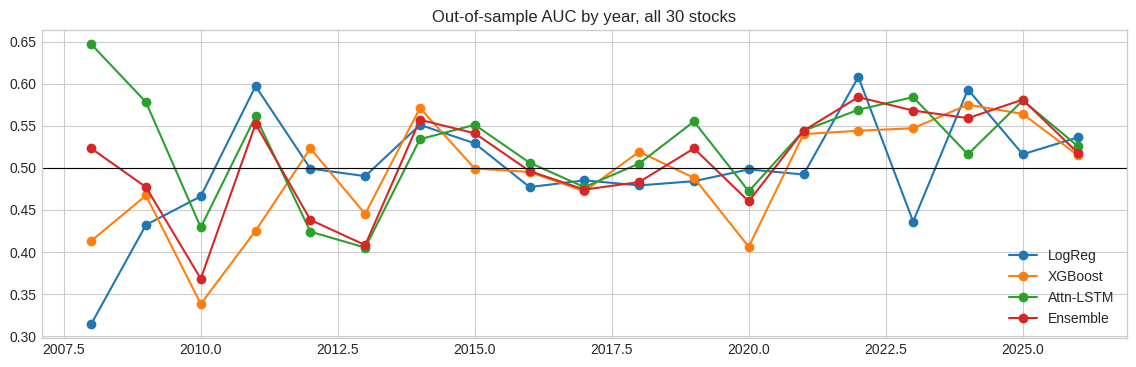

,avg_prob,win_rate,n
decile,,,
0,0.405,0.608,1299
1,0.477,0.607,1299
2,0.513,0.579,1298
3,0.539,0.569,1299
4,0.562,0.548,1298
5,0.584,0.580,1299
6,0.605,0.558,1298
7,0.628,0.536,1299
8,0.653,0.549,1298


In [9]:
Y = EV['y'].values
IS_DEV = tested & (EV['date'] < HOLD).values
IS_HO = tested & (EV['date'] >= HOLD).values
IS_T = (EV['a'] == AI).values


def auc(y, p):
    m = np.isfinite(y) & np.isfinite(p)
    return roc_auc_score(y[m], p[m]) if m.sum() > 20 and len(np.unique(y[m])) == 2 else np.nan


def brier(y, p):
    m = np.isfinite(y) & np.isfinite(p)
    return brier_score_loss(y[m], p[m]) if m.sum() else np.nan


cls = {}
for m in ALL_MODELS:
    p = probs[m]
    cls[m] = {'AUC dev (all)': auc(Y[IS_DEV], p[IS_DEV]), 'AUC hold-out (all)': auc(Y[IS_HO], p[IS_HO]),
              f'AUC dev ({TARGET})': auc(Y[IS_DEV & IS_T], p[IS_DEV & IS_T]),
              f'AUC hold-out ({TARGET})': auc(Y[IS_HO & IS_T], p[IS_HO & IS_T]),
              'Brier dev': brier(Y[IS_DEV], p[IS_DEV])}
cls['Training win rate (no model)'] = {'Brier dev': brier(Y[IS_DEV], base[IS_DEV])}
cls = pd.DataFrame(cls).T.round(4)
save_table(cls, '04_classification')
log(f'Primary-model win rate: dev {np.nanmean(Y[IS_DEV]):.1%}, hold-out {np.nanmean(Y[IS_HO]):.1%}; '
    f'{TARGET} dev {np.nanmean(Y[IS_DEV & IS_T]):.1%}, hold-out {np.nanmean(Y[IS_HO & IS_T]):.1%}')

yrs = EV['date'].dt.year.values
auc_year = pd.DataFrame({m: {yr: auc(Y[tested & (yrs == yr)], probs[m][tested & (yrs == yr)])
                             for yr in sorted(set(yrs[tested]))} for m in ALL_MODELS}).round(3)
save_table(auc_year, '04_auc_by_year')
ax = auc_year.plot(marker='o', figsize=(14, 4))
ax.axhline(0.5, color='black', lw=0.8)
ax.set_title('Out-of-sample AUC by year, all 30 stocks')
save_fig('04_auc_by_year')

# calibration: when the ensemble is more confident, do trades win more often?
dm = IS_DEV & np.isfinite(Y)
calib = pd.DataFrame({'p': probs['Ensemble'][dm], 'y': Y[dm]})
calib['decile'] = pd.qcut(calib['p'], 10, labels=False, duplicates='drop')
calib = calib.groupby('decile').agg(avg_prob=('p', 'mean'), win_rate=('y', 'mean'), n=('y', 'size')).round(3)
save_table(calib, '04_calibration_ensemble_dev')

## 7. Backtest
Decision at the close, trade at the next open, return = open-to-open, 3 bps per unit traded, long-only, no leverage.
* **Buy & hold**, **Trend 200d** (long whenever close > 200-day average).
* **Events: primary only** = every trade signal taken at full size, held until its barrier exit. Overlapping trades are averaged (AFML), so the position is between 0 and 1.
* **`<model>` filter** = take a signal only if P(win) > the training win rate.
* **`<model>` sized** = AFML bet size 2Φ(z) − 1 with z = (p − 0.5)/√(p(1−p)), floored at 0.

Results for **AAPL alone** and for an **equal-weight portfolio of all 30 stocks** (more bets, so a far more reliable comparison).

In [10]:
first_test_i = dates.searchsorted(pd.Timestamp(f"{CFG['first_test_year']}-01-01"))
R_next = np.nan_to_num((opens.shift(-1) / opens - 1).values.T)                          # open d -> open d+1
UNI = np.arange(A)


def event_positions(size):
    """Daily decision-time position from per-signal sizes (NaN = not traded): average of active bets."""
    m = np.isfinite(size)
    a, t, j, s = EV['a'].values[m], EV['t'].values[m], EV['exit_t'].values[m], size[m]
    sm, ct = np.zeros((A, T + 1)), np.zeros((A, T + 1))
    np.add.at(sm, (a, t), s)                                # active at the closes t .. exit_t - 1
    np.add.at(sm, (a, j), -s)
    np.add.at(ct, (a, t), 1)
    np.add.at(ct, (a, j), -1)
    sm, ct = sm.cumsum(1)[:, :T], ct.cumsum(1)[:, :T]
    return np.where(ct > 0.5, sm / np.maximum(ct, 1), 0.0)


def afml_size(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.clip(2 * norm.cdf((p - 0.5) / np.sqrt(p * (1 - p))) - 1, 0, 1)


def meta_positions(pr, bs, mask):
    pos = {}
    for m in ALL_MODELS:
        pos[f'{m} filter'] = event_positions(np.where(mask, (pr[m] > bs).astype(float), np.nan))
        pos[f'{m} sized'] = event_positions(np.where(mask, afml_size(pr[m]), np.nan))
    return pos


positions = {'Buy & hold': np.ones((A, T)), 'Trend 200d': TREND.astype(float),
             'Events: primary only': event_positions(np.where(tested, 1.0, np.nan)),
             **meta_positions(probs, base, tested)}


def simulate(w_dec, assets, cost_bps=None):
    """Equal capital per available stock; decision at close d, held from the open of d+1."""
    cost_bps = CFG['cost_bps'] if cost_bps is None else cost_bps
    mask = np.zeros(A, dtype=bool)
    mask[assets] = True
    avail = np.isfinite(O) & mask[:, None]
    W_dec = np.where(avail, np.nan_to_num(w_dec), 0.0) / np.maximum(avail.sum(0), 1)
    W = np.zeros_like(W_dec)
    W[:, 1:] = W_dec[:, :-1]
    dW = np.abs(np.diff(W, axis=1, prepend=0)).sum(0)
    ret = (W * R_next).sum(0) - cost_bps / 1e4 * dW
    out = pd.DataFrame({'ret': ret, 'exposure': W.sum(0), 'turnover': dW}, index=dates)
    return out.iloc[first_test_i + 1:-1]


def period(df, name):
    if name == DEV:
        return df.loc[:HOLD - pd.Timedelta(days=1)]
    if name == HO:
        return df.loc[HOLD:]
    return df


def perf_stats(sim):
    r = sim['ret']
    n = len(r)
    eq = (1 + r).cumprod()
    dd = eq / eq.cummax() - 1
    sr = r.mean() / r.std() if r.std() > 0 else np.nan
    skew, kurt = r.skew(), r.kurt() + 3
    psr = norm.cdf(sr * np.sqrt(n - 1) / np.sqrt(max(1 - skew * sr + (kurt - 1) / 4 * sr ** 2, 1e-9)))
    cagr = eq.iloc[-1] ** (252 / n) - 1
    return {'CAGR': cagr, 'Volatility': r.std() * np.sqrt(252), 'Sharpe': sr * np.sqrt(252),
            'Max drawdown': dd.min(), 'Calmar': cagr / abs(dd.min()) if dd.min() < 0 else np.nan,
            'Avg exposure': sim['exposure'].mean(), 'Turnover/yr': sim['turnover'].mean() * 252, 'PSR(SR>0)': psr}


BOOKS = {TARGET: [AI], 'Universe': UNI}
sims = {b: {k: simulate(p, ix) for k, p in positions.items()} for b, ix in BOOKS.items()}
perf = {(b, n): pd.DataFrame({k: perf_stats(period(s, n)) for k, s in sims[b].items()}).T.astype(float)
        for b in BOOKS for n in (DEV, HO)}
fmt = {**{c: '{:.1%}' for c in ['CAGR', 'Volatility', 'Max drawdown', 'Avg exposure', 'PSR(SR>0)']},
       **{c: '{:.2f}' for c in ['Sharpe', 'Calmar', 'Turnover/yr']}}
for (b, n), p in perf.items():
    log(f'\n{b}, {n}')
    save_table(p.round(4), f"05_performance_{b.lower()}_{n.split()[0].lower().replace('-', '')}",
               styler=p.style.format(fmt))
for b in BOOKS:
    pd.DataFrame({k: v['ret'] for k, v in sims[b].items()}).to_csv(os.path.join(RUN_DIR, f'daily_returns_{b.lower()}.csv'))
save_summary(performance={f'{b} {n}': p.round(4).to_dict(orient='index') for (b, n), p in perf.items()})


AAPL, Dev 2008-2022


,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Avg exposure,Turnover/yr,PSR(SR>0)
Buy & hold,22.9%,33.7%,0.78,-58.5%,0.39,100.0%,0.00,99.9%
Trend 200d,21.4%,25.0%,0.90,-33.1%,0.65,75.5%,4.47,100.0%
Events: primary only,21.4%,26.3%,0.87,-36.2%,0.59,78.1%,1.20,100.0%
LogReg filter,13.1%,20.2%,0.71,-27.8%,0.47,51.1%,4.66,99.7%
LogReg sized,3.3%,4.7%,0.70,-8.3%,0.39,10.5%,1.12,99.7%
XGBoost filter,11.1%,19.7%,0.63,-35.3%,0.31,48.8%,5.56,99.2%
XGBoost sized,2.7%,5.1%,0.54,-11.0%,0.24,10.7%,1.53,98.4%
Attn-LSTM filter,9.7%,20.3%,0.56,-33.8%,0.29,47.0%,4.52,98.4%
Attn-LSTM sized,3.9%,7.1%,0.58,-18.2%,0.22,15.7%,2.14,98.6%
Ensemble filter,10.6%,20.8%,0.59,-33.8%,0.31,50.8%,4.27,98.8%



AAPL, Hold-out 2023+


,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Avg exposure,Turnover/yr,PSR(SR>0)
Buy & hold,30.1%,27.1%,1.10,-33.3%,0.90,100.0%,0.00,98.4%
Trend 200d,20.4%,21.4%,0.98,-15.8%,1.29,80.7%,3.94,96.8%
Events: primary only,18.4%,22.4%,0.87,-25.4%,0.72,84.3%,1.31,95.1%
LogReg filter,12.4%,13.1%,0.96,-15.3%,0.81,43.5%,5.34,96.8%
LogReg sized,2.1%,2.7%,0.80,-3.5%,0.61,9.8%,0.95,93.4%
XGBoost filter,10.4%,12.7%,0.85,-16.2%,0.64,38.8%,4.66,94.6%
XGBoost sized,3.8%,2.9%,1.30,-2.9%,1.28,8.9%,1.14,99.4%
Attn-LSTM filter,11.8%,12.4%,0.96,-15.8%,0.75,31.4%,5.21,96.2%
Attn-LSTM sized,5.5%,4.1%,1.33,-5.2%,1.06,10.2%,2.04,99.4%
Ensemble filter,10.6%,11.1%,0.96,-9.1%,1.16,32.9%,4.51,96.9%



Universe, Dev 2008-2022


,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Avg exposure,Turnover/yr,PSR(SR>0)
Buy & hold,14.4%,21.1%,0.74,-45.1%,0.32,100.0%,0.00,99.8%
Trend 200d,8.3%,10.1%,0.84,-21.1%,0.39,66.6%,8.06,99.9%
Events: primary only,10.0%,11.2%,0.91,-19.2%,0.52,71.4%,2.65,100.0%
LogReg filter,5.6%,7.7%,0.75,-14.9%,0.38,41.5%,5.81,99.8%
LogReg sized,1.2%,1.7%,0.71,-3.2%,0.37,8.3%,1.11,99.6%
XGBoost filter,3.7%,7.6%,0.51,-15.4%,0.24,40.1%,5.71,97.4%
XGBoost sized,0.7%,1.9%,0.38,-4.8%,0.15,9.0%,1.42,92.6%
Attn-LSTM filter,5.9%,7.8%,0.77,-13.5%,0.44,40.5%,4.82,99.8%
Attn-LSTM sized,2.3%,2.8%,0.82,-4.1%,0.55,13.9%,2.10,99.9%
Ensemble filter,5.3%,7.9%,0.69,-15.5%,0.34,41.2%,4.92,99.5%



Universe, Hold-out 2023+


,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Avg exposure,Turnover/yr,PSR(SR>0)
Buy & hold,25.9%,15.1%,1.60,-19.7%,1.32,100.0%,0.00,99.9%
Trend 200d,14.7%,9.6%,1.48,-10.1%,1.45,68.2%,8.40,99.8%
Events: primary only,16.5%,10.5%,1.51,-12.1%,1.36,74.4%,2.61,99.8%
LogReg filter,11.7%,7.1%,1.60,-6.5%,1.80,41.3%,5.58,99.9%
LogReg sized,2.2%,1.5%,1.45,-1.6%,1.38,8.7%,1.03,99.7%
XGBoost filter,10.0%,5.9%,1.64,-5.4%,1.85,29.0%,4.54,99.9%
XGBoost sized,2.6%,1.5%,1.76,-1.2%,2.12,7.3%,1.20,100.0%
Attn-LSTM filter,9.2%,5.8%,1.55,-7.9%,1.16,28.6%,4.60,99.8%
Attn-LSTM sized,3.7%,2.0%,1.83,-2.5%,1.50,9.0%,1.68,100.0%
Ensemble filter,11.2%,5.7%,1.90,-5.0%,2.25,27.7%,4.01,100.0%


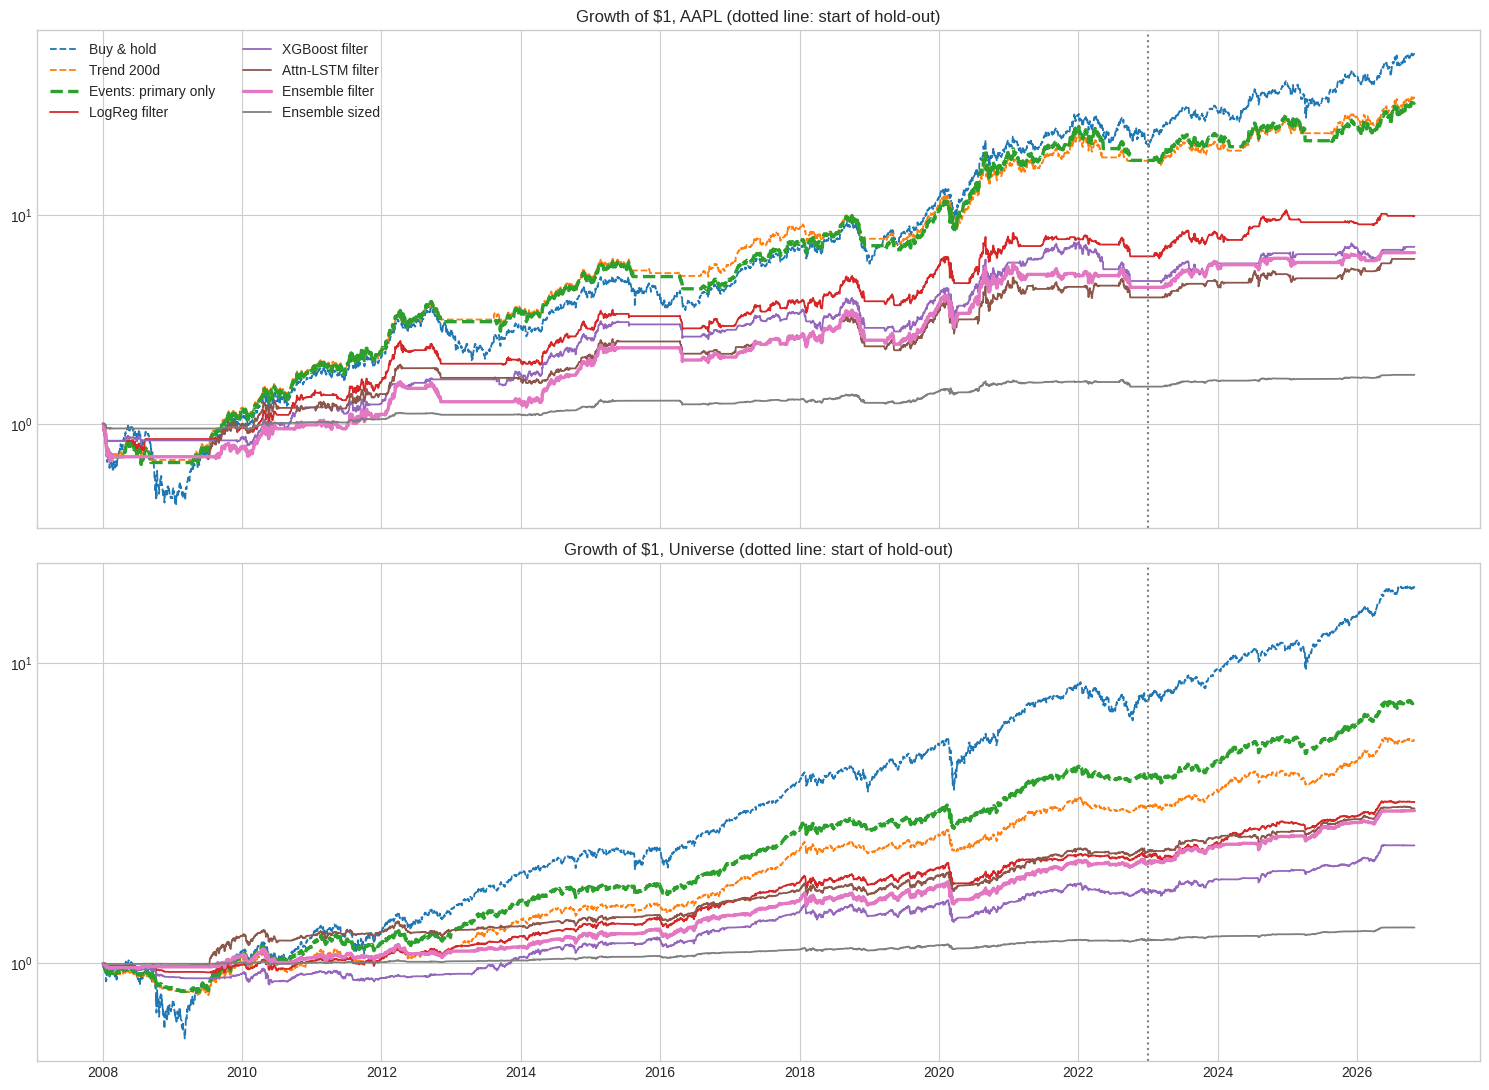

,Buy & hold,Trend 200d,Events: primary only,LogReg filter,LogReg sized,XGBoost filter,XGBoost sized,Attn-LSTM filter,Attn-LSTM sized,Ensemble filter,Ensemble sized
Date,,,,,,,,,,,
2008,-56.1%,-32.9%,-34.8%,-15.5%,-2.1%,-16.8%,-5.4%,-30.5%,-10.1%,-30.5%,-5.1%
2009,148.5%,77.8%,78.4%,13.9%,2.6%,3.5%,0.5%,43.5%,12.2%,11.7%,1.6%
2010,52.6%,52.6%,52.6%,40.7%,6.8%,39.2%,11.0%,20.0%,7.7%,27.3%,5.5%
2011,25.7%,21.2%,25.7%,18.0%,2.8%,4.5%,2.2%,16.0%,7.5%,12.2%,3.5%
2012,36.5%,43.1%,38.1%,21.5%,3.9%,30.2%,3.3%,19.6%,10.7%,14.9%,4.9%
2013,2.9%,12.8%,12.2%,3.6%,0.4%,6.1%,0.9%,-1.0%,-0.0%,0.4%,0.2%
2014,43.3%,43.3%,43.3%,42.1%,6.4%,47.9%,10.0%,28.0%,10.7%,55.1%,9.0%
2015,-6.3%,3.2%,2.3%,14.8%,3.9%,16.9%,4.1%,17.9%,13.0%,16.4%,6.9%
2016,15.4%,8.8%,-4.3%,-10.3%,-2.0%,-5.8%,-0.5%,-12.7%,-7.4%,-9.7%,-3.1%


In [11]:
show = BASELINES + [f'{m} filter' for m in ALL_MODELS] + ['Ensemble sized']
fig, ax = plt.subplots(2, 1, figsize=(15, 11), sharex=True)
for a, b in zip(ax, BOOKS):
    for k in show:
        ls = '--' if k in BASELINES else '-'
        lw = 2.4 if k in ('Events: primary only', 'Ensemble filter') else 1.3
        a.plot((1 + sims[b][k]['ret']).cumprod(), label=k, lw=lw, ls=ls)
    a.set_yscale('log')
    a.axvline(HOLD, color='grey', ls=':')
    a.set_title(f'Growth of $1, {b} (dotted line: start of hold-out)')
ax[0].legend(loc='upper left', ncol=2)
plt.tight_layout()
save_fig('05_equity_curves')

yearly = pd.DataFrame({k: (1 + v['ret']).groupby(v.index.year).prod() - 1 for k, v in sims[TARGET].items()})
save_table(yearly.round(4), f'05_yearly_returns_{TARGET.lower()}', styler=yearly.style.format('{:.1%}'))

### Shuffled-label check
All three models retrained (1 seed) with the win/loss labels shuffled inside every training window, development period only. With no information in the labels, AUC should be ≈ 0.50 and the filter strategies should not beat "primary only". If they do, something is leaking.

In [12]:
if CFG['run_shuffled_check']:
    sh_probs, sh_base, _ = walk_forward(CFG, shuffle=True, seeds=[0], last_year=HOLD.year - 1)
    sh_dev = np.isfinite(sh_base) & (EV['date'] < HOLD).values
    sh_pos = meta_positions(sh_probs, sh_base, sh_dev)
    prim_dev = perf[('Universe', DEV)].loc['Events: primary only', 'Sharpe']
    sh = {m: {'AUC shuffled': auc(Y[sh_dev], sh_probs[m][sh_dev]), 'AUC real': cls.loc[m, 'AUC dev (all)'],
              'filter Sharpe shuffled': perf_stats(period(simulate(sh_pos[f'{m} filter'], UNI), DEV))['Sharpe'],
              'filter Sharpe real': perf[('Universe', DEV)].loc[f'{m} filter', 'Sharpe'],
              'primary only Sharpe': prim_dev} for m in ALL_MODELS}
    sh = pd.DataFrame(sh).T.round(3)
    save_table(sh, '06_shuffled_label_check')
    save_summary(shuffled_check=sh.to_dict(orient='index'))

2008: train 5,430 (exits to 2007-12-21), test 383 (17 AAPL)  1.5s
2009: train 5,866 (exits to 2008-12-04), test 694 (31 AAPL)  1.5s
2010: train 6,469 (exits to 2009-12-23), test 877 (46 AAPL)  1.7s
2011: train 7,371 (exits to 2010-12-23), test 920 (50 AAPL)  5.2s
2012: train 8,310 (exits to 2011-12-21), test 916 (43 AAPL)  4.5s
2013: train 9,206 (exits to 2012-12-21), test 1,147 (17 AAPL)  2.3s
2014: train 10,324 (exits to 2013-12-23), test 1,108 (45 AAPL)  2.6s
2015: train 11,435 (exits to 2014-12-23), test 680 (29 AAPL)  3.0s
2016: train 12,140 (exits to 2015-12-22), test 854 (17 AAPL)  3.8s
2017: train 12,989 (exits to 2016-12-22), test 1,086 (45 AAPL)  6.1s
2018: train 14,049 (exits to 2017-12-21), test 973 (45 AAPL)  3.3s
2019: train 15,080 (exits to 2018-12-21), test 852 (30 AAPL)  3.9s
2020: train 15,913 (exits to 2019-12-23), test 742 (44 AAPL)  4.5s
2021: train 16,641 (exits to 2020-12-23), test 1,184 (47 AAPL)  3.9s
2022: train 17,813 (exits to 2021-12-23), test 570 (22 AAPL)

,AUC shuffled,AUC real,filter Sharpe shuffled,filter Sharpe real,primary only Sharpe
LogReg,0.487,0.495,0.700,0.748,0.905
XGBoost,0.484,0.461,0.690,0.513,0.905
Attn-LSTM,0.505,0.496,0.880,0.770,0.905
Ensemble,0.491,0.480,0.789,0.691,0.905


## 8. Statistical comparison
Block bootstrap (1-month blocks): probability that each strategy's Sharpe beats "Events: primary only", "Trend 200d" and "Buy & hold". Cost sensitivity at 0, 3 and 10 bps.

In [13]:
def bootstrap_sharpe_diff(a, b_, block=21, reps=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(a)
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(reps, nb))
    ix = (starts[:, :, None] + np.arange(block)).reshape(reps, -1)[:, :n]
    A_, B_ = a[ix], b_[ix]
    d = (A_.mean(1) / (A_.std(1) + 1e-12) - B_.mean(1) / (B_.std(1) + 1e-12)) * np.sqrt(252)
    return (d > 0).mean(), np.median(d)


BENCHES = ['Events: primary only', 'Trend 200d', 'Buy & hold']
boot_rows = []
for b in BOOKS:
    for n in (DEV, HO):
        for k in STRATS:
            row = {'book': b, 'period': n, 'strategy': k}
            for bench in BENCHES:
                if k != bench:
                    pb, med = bootstrap_sharpe_diff(period(sims[b][k], n)['ret'].values,
                                                    period(sims[b][bench], n)['ret'].values)
                    row[f'P(beats {bench})'] = pb
                    row[f'median diff vs {bench}'] = med
            boot_rows.append(row)
boot = pd.DataFrame(boot_rows).set_index(['book', 'period', 'strategy']).round(3)
save_table(boot, '07_bootstrap')
save_summary(bootstrap=boot.reset_index().to_dict(orient='records'))

sens = {}
for c in [0, 3, 10]:
    for k, p in positions.items():
        for b, ix in BOOKS.items():
            sens[(k, f'{b} dev {c}bps')] = perf_stats(period(simulate(p, ix, cost_bps=c), DEV))['Sharpe']
save_table(pd.Series(sens).unstack().round(2), '07_cost_sensitivity_sharpe')

P(beats Events: primary only)  median diff vs Events: primary only  P(beats Trend 200d)  median diff vs Trend 200d  \
book     period         strategy                                                                                                                                   
AAPL     Dev 2008-2022  Buy & hold                                    0.310                               -0.080                0.228                     -0.124   
                        Trend 200d                                    0.720                                0.048                  NaN                        NaN   
                        Events: primary only                            NaN                                  NaN                0.280                     -0.048   
                        LogReg filter                                 0.112                               -0.165                0.073                     -0.210   
                        LogReg sized                                  0.102                               -0.201                0.060                     -0.245   
                        XGBoost filter                                0.043                               -0.244                0.026                     -0.283   
                        XGBoost sized                                 0.029                               -0.316                0.015                     -0.365   
                        Attn-LSTM filter                              0.030                               -0.295                0.027                     -0.346   
                        Attn-LSTM sized                               0.080                               -0.294                0.078                     -0.342   
                        Ensemble filter                               0.028                               -0.275                0.028                     -0.329   
                        Ensemble sized                                0.047                               -0.277                0.036                     -0.325   
         Hold-out 2023+ Buy & hold                                    0.899                                0.213                0.678                      0.120   
                        Trend 200d                                    0.707                                0.096                  NaN                        NaN   
                        Events: primary only                            NaN                                  NaN                0.293                     -0.096   
                        LogReg filter                                 0.598                                0.105                0.500                      0.001   
                        LogReg sized                                  0.446                               -0.039                0.304                     -0.163   
                        XGBoost filter                                0.479                               -0.028                0.388                     -0.118   
                        XGBoost sized                                 0.836                                0.416                0.768                      0.330   
                        Attn-LSTM filter                              0.613                                0.123                0.514                      0.010   
                        Attn-LSTM sized                               0.894                                0.488                0.856                      0.374   
                        Ensemble filter                               0.585                                0.107                0.496                     -0.004   
                        Ensemble sized                                0.906                                0.523                0.866                      0.417   
Universe Dev 2008-2022  Buy & hold                                    0.112                               -0.1

,AAPL dev 0bps,AAPL dev 10bps,AAPL dev 3bps,Universe dev 0bps,Universe dev 10bps,Universe dev 3bps
Attn-LSTM filter,0.57,0.55,0.56,0.79,0.73,0.77
Attn-LSTM sized,0.59,0.56,0.58,0.84,0.77,0.82
Buy & hold,0.78,0.78,0.78,0.74,0.74,0.74
Ensemble filter,0.59,0.57,0.59,0.71,0.65,0.69
Ensemble sized,0.61,0.58,0.60,0.67,0.61,0.65
Events: primary only,0.87,0.87,0.87,0.91,0.89,0.91
LogReg filter,0.72,0.70,0.71,0.77,0.70,0.75
LogReg sized,0.71,0.68,0.70,0.73,0.66,0.71
Trend 200d,0.90,0.89,0.90,0.86,0.78,0.84
XGBoost filter,0.64,0.61,0.63,0.54,0.46,0.51


## 9. Verdict
The best meta strategy is chosen on the **30-stock universe, development period only**. It counts as adding value only if it beats "Events: primary only" in the universe development bootstrap (≥ 90%) **and** has a higher development Sharpe than "primary only" on AAPL. Otherwise the recommendation is the best baseline. The 2023+ hold-out is reported, not used.

AAPL Dev 2008-2022                                  AAPL Hold-out 2023+                                  Universe Dev 2008-2022         \
                                   CAGR Sharpe Max drawdown Avg exposure                CAGR Sharpe Max drawdown Avg exposure                   CAGR Sharpe   
Buy & hold                        0.229  0.780       -0.585        1.000               0.301  1.104       -0.333        1.000                  0.144  0.745   
Trend 200d                        0.214  0.899       -0.331        0.755               0.204  0.976       -0.158        0.807                  0.083  0.839   
Events: primary only              0.214  0.870       -0.362        0.781               0.184  0.868       -0.254        0.843                  0.100  0.905   
LogReg filter                     0.131  0.712       -0.278        0.511               0.124  0.959       -0.153        0.435                  0.056  0.748   
LogReg sized                      0.033  0.701       -0.083        0.105               0.021  0.801       -0.035        0.098                  0.012  0.709   
XGBoost filter                    0.111  0.633       -0.353        0.488               0.104  0.845       -0.162        0.388                  0.037  0.513   
XGBoost sized                     0.027  0.540       -0.110        0.107               0.038  1.296       -0.029        0.089                  0.007  0.383   
Attn-LSTM filter                  0.097  0.561       -0.338        0.470               0.118  0.961       -0.158        0.314                  0.059  0.770   
Attn-LSTM sized                   0.039  0.578       -0.182        0.157               0.055  1.334       -0.052        0.102                  0.023  0.821   
Ensemble filter                   0.106  0.586       -0.338        0.508               0.106  0.962       -0.091        0.329                  0.053  0.691   
Ensemble sized                    0.028  0.600       -0.098        0.109               0.035  1.390       -0.019        0.077                  0.012  0.652   

                                               Universe Hold-out 2023+                                   
                     Max drawdown Avg exposure                    CAGR Sharpe Max drawdown Avg exposure  
Buy & hold                 -0.451        1.000                   0.259  1.599       -0.197        1.000  
Trend 200d                 -0.211        0.666                   0.147  1.484       -0.101        0.682  
Events: primary only       -0.192        0.714                   0.165  1.514       -0.121        0.744  
LogReg filter              -0.149        0.415                   0.117  1.599       -0.065        0.413  
LogReg sized               -0.032        0.083                   0.022  1.450       -0.016        0.087  
XGBoost filter             -0.154        0.401                   0.100  1.640       -0.054        0.290  
XGBoost sized              -0.048        0.090                   0.026  1.758       -0.012        0.073  
Attn-LSTM filter           -0.135        0.405                   0.092  1.549       -0.079        0.286  
Attn-LSTM sized            -0.041        0.139                   0.037  1.829       -0.025        0.090  
Ensemble filter            -0.155        0.412                   0.112  1.898       -0.050        0.277  
Ensemble sized             -0.037        0.090                   0.026  1.920       -0.010        0.067

Best meta strategy on universe development: Attn-LSTM sized. Sharpe AAPL Dev 0.58 (primary only 0.87), AAPL Hold-out 1.33 (primary only 0.87), Universe Dev 0.82 (primary only 0.91), Universe Hold-out 1.83 (primary only 1.51)
P(beats primary only), universe dev: 28%  ->  NO evidence meta-labeling adds value. Recommended: Events: primary only


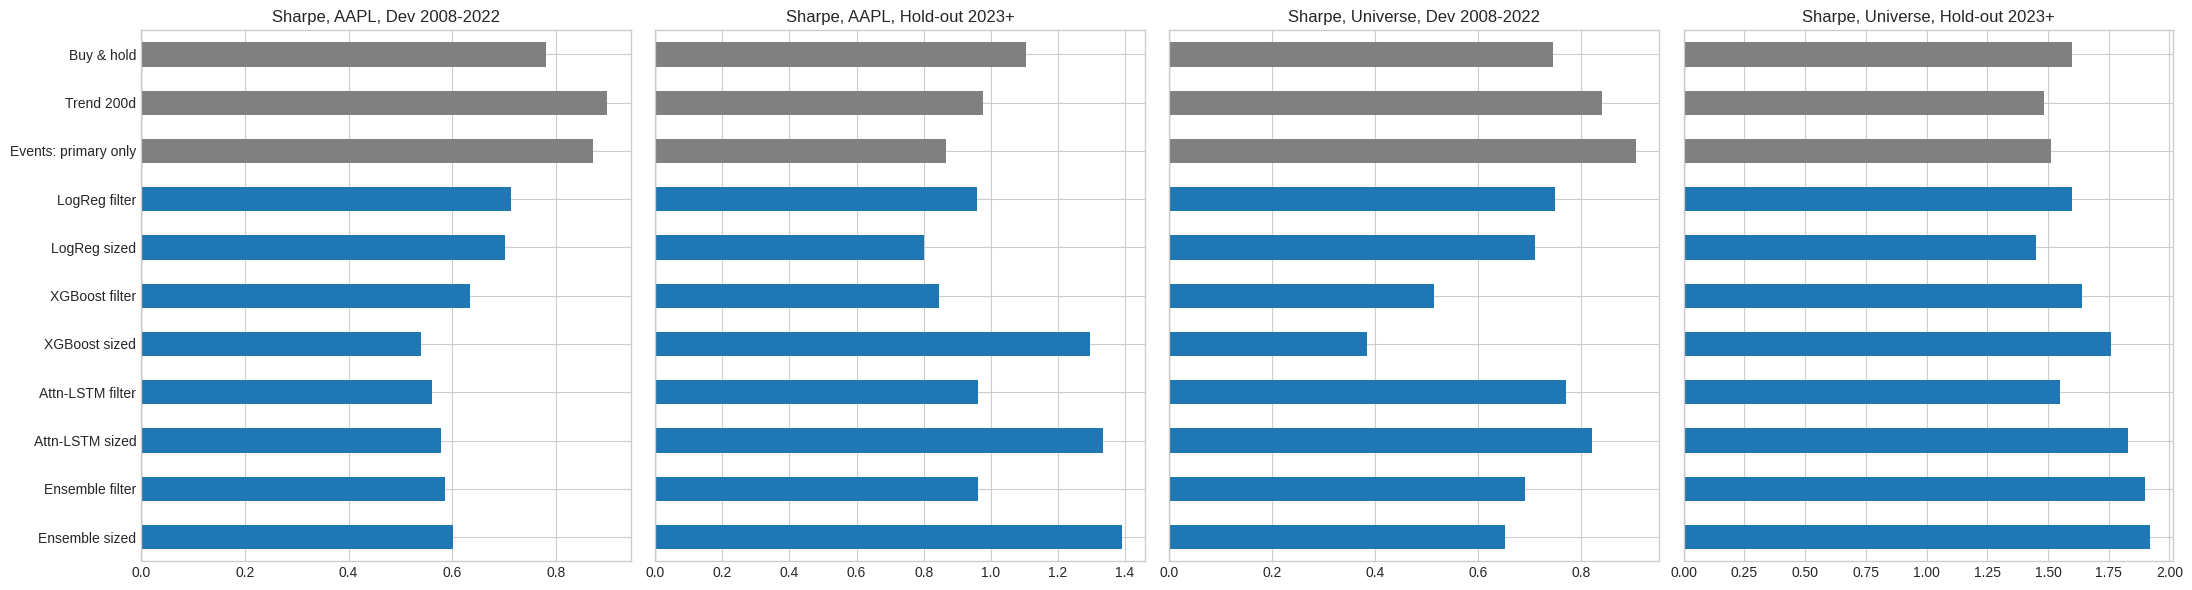

In [14]:
best = perf[('Universe', DEV)].loc[META, 'Sharpe'].idxmax()
p_uni = boot.loc[('Universe', DEV, best), 'P(beats Events: primary only)']
improves = bool(p_uni >= 0.9 and perf[(TARGET, DEV)].loc[best, 'Sharpe'] > perf[(TARGET, DEV)].loc['Events: primary only', 'Sharpe'])
best_base = perf[('Universe', DEV)].loc[BASELINES, 'Sharpe'].idxmax()
RECOMMENDED = best if improves else best_base
cmp_cols = ['CAGR', 'Sharpe', 'Max drawdown', 'Avg exposure']
save_table(pd.concat({f'{b} {n}': perf[(b, n)][cmp_cols] for b in BOOKS for n in (DEV, HO)}, axis=1).round(3), '08_verdict')
log(f'Best meta strategy on universe development: {best}. Sharpe ' + ', '.join(
    f"{b} {n.split()[0]} {perf[(b, n)].loc[best, 'Sharpe']:.2f} (primary only {perf[(b, n)].loc['Events: primary only', 'Sharpe']:.2f})"
    for b in BOOKS for n in (DEV, HO)))
log(f"P(beats primary only), universe dev: {p_uni:.0%}  ->  "
    f"{'meta-labeling ADDS value' if improves else 'NO evidence meta-labeling adds value'}. Recommended: {RECOMMENDED}")

fig, ax = plt.subplots(1, 4, figsize=(22, 6), sharey=True)
for a, (b, n) in zip(ax, [(b, n) for b in BOOKS for n in (DEV, HO)]):
    perf[(b, n)]['Sharpe'].loc[STRATS].plot.barh(ax=a, color=['grey'] * len(BASELINES) + ['tab:blue'] * len(META))
    a.axvline(0, color='black', lw=0.8)
    a.set_title(f'Sharpe, {b}, {n}')
ax[0].invert_yaxis()
plt.tight_layout()
save_fig('08_sharpe_comparison')
save_summary(best_meta_dev=best, p_beats_primary_universe_dev=p_uni, meta_adds_value=improves, recommended=RECOMMENDED)

## 10. Today's signal and the forward paper-trading log
AAPL position for the next open under every strategy. Each run appends them to `results/forward_log_v7.csv`, and each later run scores logged positions on the 5 trading days that followed: out-of-sample in the strict sense.

In [ ]:
last = T - 1
le = EV.index[EV['a'] == AI][-1]
state = pd.Series({'data date': dates[last].date(), f'{TARGET} close': round(closes[TARGET].iloc[-1], 2),
                   f'above {CFG["trend_window"]}-day average': bool(TREND[AI, last]),
                   'CUSUM event today': bool(CUSUM[AI, last]), 'last trade signal': EV.loc[le, 'date'].date(),
                   **{f'P(win) {m}': round(float(probs[m][le]), 3) for m in ALL_MODELS},
                   'training win rate': round(float(base[le]), 3)}, name=TARGET)
save_table(state.to_frame(), '09_today_state')
live = pd.Series({k: positions[k][AI, last] for k in STRATS}, name=f'{TARGET} position at next open').round(3)
save_table(live.to_frame(), '09_live_positions')
log(f"Recommended ({RECOMMENDED}): {TARGET} position {live[RECOMMENDED]:.2f} at the next open")

new = pd.DataFrame({'run_id': RUN_ID, 'data_date': dates[last].date().isoformat(),
                    'strategy': live.index, 'position': live.values})
old = pd.read_csv(FORWARD_LOG) if os.path.exists(FORWARD_LOG) else pd.DataFrame(columns=new.columns)
flog = pd.concat([old, new]).drop_duplicates(['data_date', 'strategy'], keep='last')
flog.to_csv(FORWARD_LOG, index=False)
log(f'Forward log: {flog["data_date"].nunique()} signal dates stored in {FORWARD_LOG}')

rows = []
for _, r in flog.iterrows():
    i = dates.searchsorted(pd.Timestamp(r['data_date']))
    if i + 6 < T and dates[i] == pd.Timestamp(r['data_date']):
        rows.append({'data_date': r['data_date'], 'strategy': r['strategy'],
                     '5-day return': r['position'] * (O[AI, i + 6] / O[AI, i + 1] - 1)})
if rows:
    fwd_perf = pd.DataFrame(rows).pivot(index='data_date', columns='strategy', values='5-day return')
    save_table(fwd_perf.round(4), '10_forward_paper_trading')
else:
    log('Forward paper-trading: no logged signal has 5 days of later data yet. Rerun next week to start scoring.')
save_summary(status='complete')
log(f'Run complete. Everything is saved in {RUN_DIR}')

## Caveats
* **Survivorship bias:** the 30 stocks are today's well-known large caps. Stocks that collapsed or were delisted are missing, which flatters buy & hold and long-only trend trades in the universe book. The comparison *between* meta strategies and "primary only" is less affected, since both trade the same names.
* AAPL's 2023+ period was seen in v3, and the design choices draw on v2–v6, so the hold-out is not fully clean; the forward log is.
* Costs are a flat 3 bps per unit traded: no extra slippage at the open, taxes or financing. Prices are dividend-adjusted.
* Past out-of-sample performance is not a forecast. Paper-trade before risking money.